# US Salary Prediction
**Goal:** predict the estimated annual salary of US data-related jobs using Glassdoor job-posting data.

**Workflow**
1. Load and inspect the dataset
2. Clean salary and job information
3. Explore salary patterns
4. Prepare features for machine learning
5. Train and compare regression models
6. Evaluate results and predict a sample job

## Step 1: Import libraries and load the data

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")


In [3]:
df = pd.read_csv("C:/Users/hp/Downloads/glassdoor_jobs (1).csv")

print("Rows and columns:", df.shape)
df.head()

Rows and columns: (956, 15)


,Unnamed: 0,Job Title,Salary Estimate,Job Description,Rating,Company Name,Location,Headquarters,Size,Founded,Type of ownership,Industry,Sector,Revenue,Competitors
0,0,Data Scientist,$53K-$91K (Glassdoor est.),"Data Scientist\nLocation: Albuquerque, NM\nEdu...",3.8,Tecolote Research\n3.8,"Albuquerque, NM","Goleta, CA",501 to 1000 employees,1973,Company - Private,Aerospace & Defense,Aerospace & Defense,$50 to $100 million (USD),-1
1,1,Healthcare Data Scientist,$63K-$112K (Glassdoor est.),What You Will Do:\n\nI. General Summary\n\nThe...,3.4,University of Maryland Medical System\n3.4,"Linthicum, MD","Baltimore, MD",10000+ employees,1984,Other Organization,Health Care Services & Hospitals,Health Care,$2 to $5 billion (USD),-1
2,2,Data Scientist,$80K-$90K (Glassdoor est.),"KnowBe4, Inc. is a high growth information sec...",4.8,KnowBe4\n4.8,"Clearwater, FL","Clearwater, FL",501 to 1000 employees,2010,Company - Private,Security Services,Business Services,$100 to $500 million (USD),-1
3,3,Data Scientist,$56K-$97K (Glassdoor est.),*Organization and Job ID**\nJob ID: 310709\n\n...,3.8,PNNL\n3.8,"Richland, WA","Richland, WA",1001 to 5000 employees,1965,Government,Energy,"Oil, Gas, Energy & Utilities",$500 million to $1 billion (USD),"Oak Ridge National Laboratory, National Renewa..."
4,4,Data Scientist,$86K-$143K (Glassdoor est.),Data Scientist\nAffinity Solutions / Marketing...,2.9,Affinity Solutions\n2.9,"New York, NY","New York, NY",51 to 200 employees,1998,Company - Private,Advertising & Marketing,Business Services,Unknown / Non-Applicable,"Commerce Signals, Cardlytics, Yodlee"


In [4]:
# Column names, data types and missing values
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 956 entries, 0 to 955
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Unnamed: 0         956 non-null    int64  
 1   Job Title          956 non-null    object 
 2   Salary Estimate    956 non-null    object 
 3   Job Description    956 non-null    object 
 4   Rating             956 non-null    float64
 5   Company Name       956 non-null    object 
 6   Location           956 non-null    object 
 7   Headquarters       956 non-null    object 
 8   Size               956 non-null    object 
 9   Founded            956 non-null    int64  
 10  Type of ownership  956 non-null    object 
 11  Industry           956 non-null    object 
 12  Sector             956 non-null    object 
 13  Revenue            956 non-null    object 
 14  Competitors        956 non-null    object 
dtypes: float64(1), int64(2), object(12)
memory usage: 112.2+ KB


## Step 2: Clean the data

Things we do:
* Glassdoor writes missing values as `-1`, so we turn them into proper missing values (NaN).
* The salary looks like `"$53K-$91K (Glassdoor est.)"`. We convert it into one number: the average in **thousands of dollars** (this is our target).
* Created useful new columns (state, company age, skills mentioned in the description, simple job title, seniority).

In [5]:
# 1) Replacing -1 with missing values
df = df.replace({-1: np.nan, "-1": np.nan, -1.0: np.nan})

# Dropping the useless index column if it exists
df = df.drop(columns=[c for c in df.columns if c.startswith("Unnamed")], errors="ignore")

In [6]:
# 2) Turn the salary text into numbers
def parse_salary(text):
    """'$53K-$91K (Glassdoor est.)' -> (53, 91) in thousands of dollars per year"""
    if pd.isna(text):
        return np.nan, np.nan
    t = str(text).lower()
    is_hourly = "per hour" in t
    t = re.sub(r"\(.*?\)", "", t)                       # remove text in brackets
    t = t.replace("employer provided salary:", "").replace("per hour", "")
    t = t.replace("$", "").replace("k", "")
    numbers = [float(n) for n in re.findall(r"\d+\.?\d*", t)]
    if not numbers:
        return np.nan, np.nan
    low, high = numbers[0], numbers[-1]
    if is_hourly:                                         # hourly -> yearly (in thousands)
        low, high = low * 2080 / 1000, high * 2080 / 1000
    return low, high

salaries = df["Salary Estimate"].apply(parse_salary)
df["min_salary"] = salaries.str[0]
df["max_salary"] = salaries.str[1]
df["avg_salary"] = (df["min_salary"] + df["max_salary"]) / 2    # <-- our TARGET (in K USD)


df = df.dropna(subset=["avg_salary"])
print("Rows after removing missing salary:", len(df))
df[["Salary Estimate", "min_salary", "max_salary", "avg_salary"]].head()

Rows after removing missing salary: 742


,Salary Estimate,min_salary,max_salary,avg_salary
0,$53K-$91K (Glassdoor est.),53.0,91.0,72.0
1,$63K-$112K (Glassdoor est.),63.0,112.0,87.5
2,$80K-$90K (Glassdoor est.),80.0,90.0,85.0
3,$56K-$97K (Glassdoor est.),56.0,97.0,76.5
4,$86K-$143K (Glassdoor est.),86.0,143.0,114.5


In [7]:
# 3) Create new columns

# State of the job and of the company headquarters (e.g. "Boston, MA" -> "MA")
df["job_state"] = df["Location"].astype(str).str.split(",").str[-1].str.strip()
df["hq_state"] = df["Headquarters"].astype(str).str.split(",").str[-1].str.strip()
df.loc[df["Headquarters"].isna(), "hq_state"] = np.nan

# 1 if the job is in the same state as the headquarters
df["same_state"] = (df["job_state"] == df["hq_state"]).astype(int)

# Age of the company
df["age"] = 2026 - pd.to_numeric(df["Founded"], errors="coerce")

# Length of the job description
df["desc_len"] = df["Job Description"].fillna("").str.len()

# Skills mentioned in the description (1 = yes, 0 = no)
desc = df["Job Description"].fillna("").str.lower()
df["python"] = desc.str.contains("python").astype(int)
df["excel"] = desc.str.contains("excel").astype(int)
df["sql"] = desc.str.contains(r"\bsql\b").astype(int)
df["spark"] = desc.str.contains("spark").astype(int)
df["aws"] = desc.str.contains(r"\baws\b").astype(int)
df["tableau"] = desc.str.contains("tableau").astype(int)
df["tensorflow"] = desc.str.contains("tensorflow").astype(int)
df["hadoop"] = desc.str.contains("hadoop").astype(int)

# Simplify the job title into a few groups
def simplify_title(title):
    title = title.lower()
    if "data scientist" in title or "data science" in title:
        return "data scientist"
    if "data engineer" in title:
        return "data engineer"
    if "analyst" in title:
        return "analyst"
    if "machine learning" in title:
        return "machine learning"
    if "manager" in title:
        return "manager"
    if "director" in title:
        return "director"
    return "other"

df["job_simp"] = df["Job Title"].astype(str).apply(simplify_title)

# Seniority from the job title
def seniority(title):
    title = title.lower()
    if any(w in title for w in ["sr.", "sr ", "senior", "lead", "principal", "staff"]):
        return "senior"
    if any(w in title for w in ["jr", "junior", "entry"]):
        return "junior"
    return "not specified"

df["seniority"] = df["Job Title"].astype(str).apply(seniority)

# Rename a few columns to simpler names
df = df.rename(columns={"Rating": "rating", "Size": "size", "Type of ownership": "ownership",
                        "Industry": "industry", "Sector": "sector", "Revenue": "revenue"})
df["rating"] = pd.to_numeric(df["rating"], errors="coerce")

df[["job_simp", "seniority", "job_state", "same_state", "age", "python", "sql"]].head()

,job_simp,seniority,job_state,same_state,age,python,sql
0,data scientist,not specified,NM,0,53.0,1,0
1,data scientist,not specified,MD,1,42.0,1,0
2,data scientist,not specified,FL,1,16.0,1,1
3,data scientist,not specified,WA,1,61.0,1,0
4,data scientist,not specified,NY,1,28.0,1,1


In [8]:
# Keep only the columns we need and save the clean file
columns_to_keep = ["avg_salary", "rating", "age", "desc_len", "same_state",
                   "python", "excel", "sql", "spark", "aws", "tableau", "tensorflow", "hadoop",
                   "job_simp", "seniority", "job_state", "hq_state",
                   "size", "ownership", "industry", "sector", "revenue"]
clean = df[columns_to_keep].reset_index(drop=True)
clean.to_csv("clean_data.csv", index=False)

print("Clean data shape:", clean.shape)
print("\nMissing values per column:")
print(clean.isna().sum()[clean.isna().sum() > 0])

Clean data shape: (742, 22)

Missing values per column:
rating       11
age          50
hq_state      1
size          1
ownership     1
industry     10
sector       10
revenue       1
dtype: int64


## Step 3: Exploratory Data Analysis (EDA)
Let's look at the data with charts to understand what affects salary.

In [9]:
# Basic statistics of the salary (in thousands of dollars)
clean["avg_salary"].describe()

count    742.000000
mean     101.499326
std       37.463032
min       15.500000
25%       73.500000
50%       97.500000
75%      122.500000
max      254.000000
Name: avg_salary, dtype: float64

C:\Users\hp\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


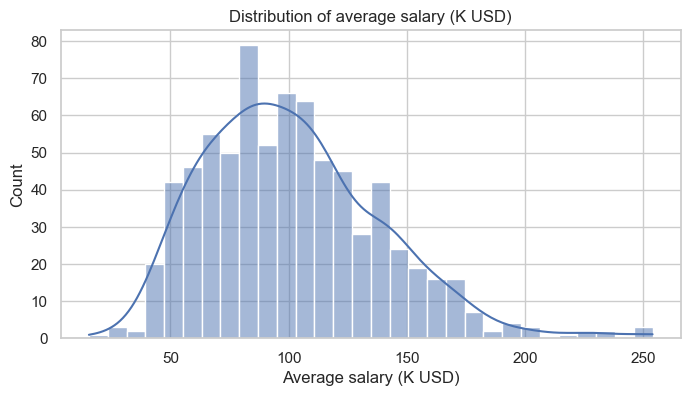

In [10]:
# How is the salary distributed?
plt.figure(figsize=(8, 4))
sns.histplot(clean["avg_salary"], bins=30, kde=True)
plt.title("Distribution of average salary (K USD)")
plt.xlabel("Average salary (K USD)")
plt.show()

#### Chart Conclusion

The salary distribution shows how salaries are spread across the dataset. The central peak indicates the most common salary range, while a long tail or isolated bars indicate a smaller number of unusually high or low salaries. Such extreme values can affect regression errors, so the distribution should be considered when interpreting model performance.

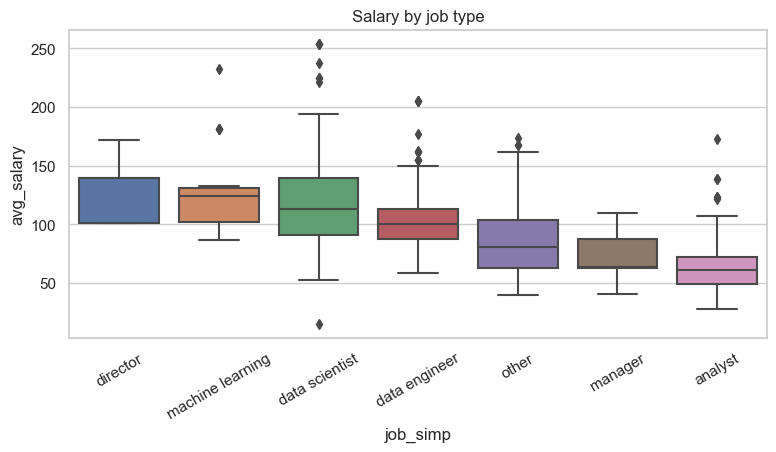

In [11]:
# Salary by job type
order = clean.groupby("job_simp")["avg_salary"].median().sort_values(ascending=False).index
plt.figure(figsize=(9, 4))
sns.boxplot(data=clean, x="job_simp", y="avg_salary", order=order)
plt.title("Salary by job type")
plt.xticks(rotation=30)
plt.show()

#### Chart Conclusion
The boxplots compare salary levels across job types. Differences in median lines suggest that typical salaries vary by role, while wide boxes and long whiskers indicate greater variation within a job category. Overlapping distributions mean job type alone may not fully explain salary differences.

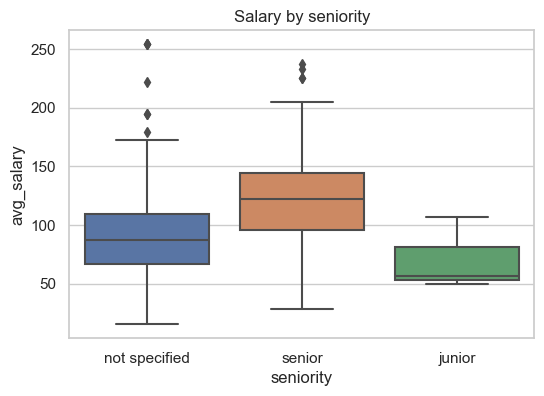

In [12]:
# Salary by seniority
plt.figure(figsize=(6, 4))
sns.boxplot(data=clean, x="seniority", y="avg_salary")
plt.title("Salary by seniority")
plt.show()

#### Chart Conclusion
This chart compares salaries across seniority levels. Compare the median lines to see whether more senior roles tend to have higher typical salaries. Overlap between groups suggests that seniority is useful but does not determine salary on its own; role, location, company, and skills can also matter.

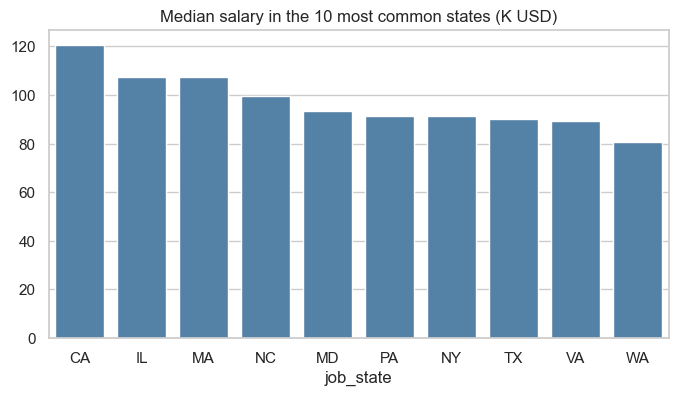

In [13]:
# Top 10 states by number of jobs - and their median salary
top_states = clean["job_state"].value_counts().head(10).index
state_salary = (clean[clean["job_state"].isin(top_states)]
                .groupby("job_state")["avg_salary"].median().sort_values(ascending=False))

plt.figure(figsize=(8, 4))
sns.barplot(x=state_salary.index, y=state_salary.values, color="steelblue")
plt.title("Median salary in the 10 most common states (K USD)")
plt.show()

#### Chart Conclusion
This chart compares median salaries for the ten states with the most job listings. The ranking highlights geographic differences in typical pay within this subset. These are medians for the selected states, not necessarily a ranking of every state, and differences may also reflect job mix and cost of living.

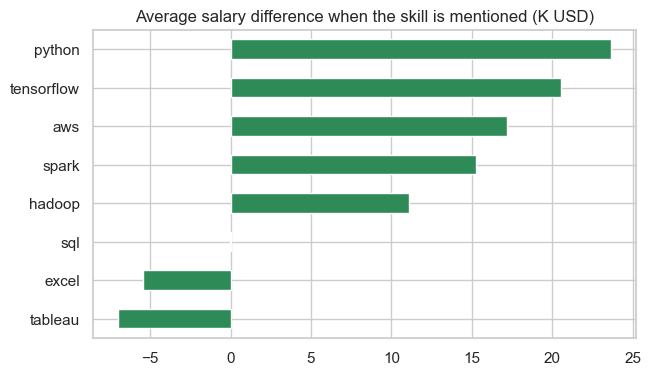

In [14]:
# Do jobs that mention a skill pay more?
skills = ["python", "excel", "sql", "spark", "aws", "tableau", "tensorflow", "hadoop"]
uplift = {}
for s in skills:
    uplift[s] = clean[clean[s] == 1]["avg_salary"].mean() - clean[clean[s] == 0]["avg_salary"].mean()

pd.Series(uplift).sort_values().plot(kind="barh", figsize=(7, 4), color="seagreen")
plt.title("Average salary difference when the skill is mentioned (K USD)")
plt.show()

#### Chart Conclusion
The bars show the difference in average salary between jobs that mention each skill and jobs that do not. Positive values indicate a higher average salary for listings mentioning that skill; negative values indicate a lower average. This is an association, not proof that the skill causes higher pay, because experience, role, and location may differ between groups.

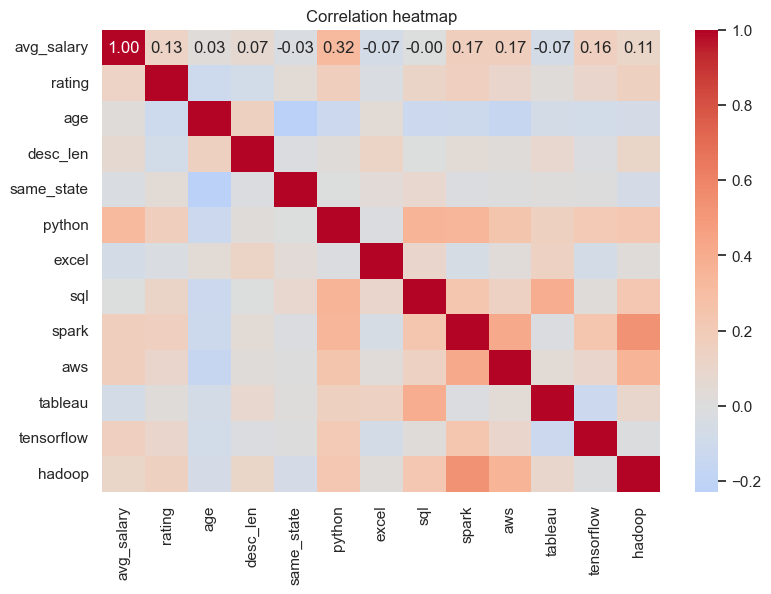

In [15]:
# Correlation between the numeric columns
plt.figure(figsize=(9, 6))
sns.heatmap(clean.select_dtypes("number").corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation heatmap")
plt.show()

#### Chart Conclusion
The heatmap shows correlations between numerical variables. Values closer to +1 indicate a stronger positive linear relationship, values closer to −1 indicate a stronger negative relationship, and values near 0 indicate a weak linear relationship. Correlation does not imply causation, and correlations between input features may indicate redundancy.

## Step 4: Prepare data for machine learning

We separate the target salary from the input features. Missing numeric values are filled with the median, and text categories are encoded using one-hot encoding. The same preprocessing is applied consistently to training and test data.

In [16]:
data = clean.copy()

y = data["avg_salary"]  # target: average salary in thousands of USD
X = data.drop(columns=["avg_salary"])

# Identify numeric and categorical columns
numeric_cols = X.select_dtypes(include="number").columns.tolist()
categorical_cols = X.select_dtypes(exclude="number").columns.tolist()

numeric_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_preprocessor, numeric_cols),
    ("categorical", categorical_preprocessor, categorical_cols)
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Numeric features:", len(numeric_cols))
print("Categorical features:", len(categorical_cols))


Training rows: 593
Testing rows: 149
Numeric features: 12
Categorical features: 9


## Step 5: Train and evaluate regression models
We start with three common regression models. Salaries are kept in their original unit (thousands of USD), so we do not need to apply log1p or expm1.

Metrics:
- MAE: average absolute prediction error (lower is better)
- RMSE: penalizes larger errors more heavily (lower is better)
- R²: proportion of salary variation explained by the model (closer to 1 is better)
  
The reference project reports an R² around 0.72 in its own setup. This notebook calculates its own score; it does not force the result to 0.72.

In [17]:
# Build simple pipelines so preprocessing is fitted only on training data
models = {
    "Linear Regression": Pipeline([
        ("preprocessing", preprocessor),
        ("model", LinearRegression())
    ]),
    "Ridge Regression": Pipeline([
        ("preprocessing", preprocessor),
        ("model", Ridge(alpha=10.0))
    ]),
    "Random Forest": Pipeline([
        ("preprocessing", preprocessor),
        ("model", RandomForestRegressor(
            n_estimators=150, min_samples_leaf=2, random_state=42, n_jobs=-1
        ))
    ]),
    "Gradient Boosting": Pipeline([
        ("preprocessing", preprocessor),
        ("model", GradientBoostingRegressor(
            n_estimators=150, learning_rate=0.05, max_depth=3, random_state=42
        ))
    ])
}

In [18]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

results = []
predictions = {}

for name, model in models.items():
    print("Training", name, "...")

    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    # Check for invalid predictions
    if not np.isfinite(pred).all():
        print(f"Skipping {name}: predictions contain NaN or infinity.")
        continue

    predictions[name] = pred

    results.append({
        "Model": name,
        "MAE (K USD)": mean_absolute_error(y_test, pred),
        "RMSE (K USD)": np.sqrt(mean_squared_error(y_test, pred)),
        "R2": r2_score(y_test, pred)
    })

results = pd.DataFrame(results)

if not results.empty:
    results = results.sort_values("MAE (K USD)").round(3)

results

Training Linear Regression ...
Training Ridge Regression ...
Training Random Forest ...
Training Gradient Boosting ...


,Model,MAE (K USD),RMSE (K USD),R2
2,Random Forest,12.592,19.046,0.769
3,Gradient Boosting,17.841,23.013,0.662
0,Linear Regression,19.651,27.051,0.533
1,Ridge Regression,19.702,26.330,0.558


## Step 6: Compare the models

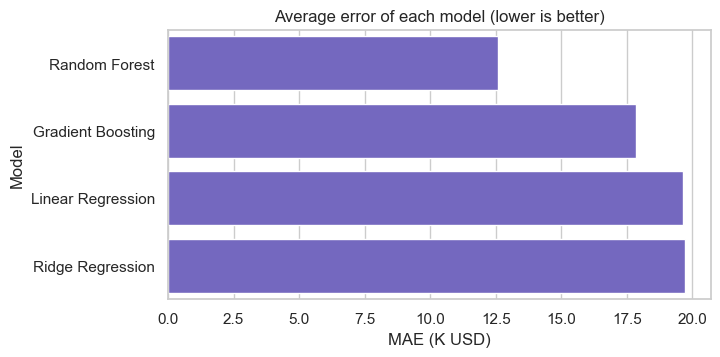

Best model: Random Forest


In [19]:
# Which model has the smallest error?
plt.figure(figsize=(7, 3.5))
sns.barplot(data=results, y="Model", x="MAE (K USD)", color="slateblue")
plt.title("Average error of each model (lower is better)")
plt.show()

best_name = results.iloc[0]["Model"]
print("Best model:", best_name)

MAE measures the average absolute prediction error in K USD, so lower values indicate better predictions on the test set. The model with the smallest MAE is selected as the best model by this criterion. Compare this chart with RMSE and R² as well, because each metric captures a different aspect of performance.

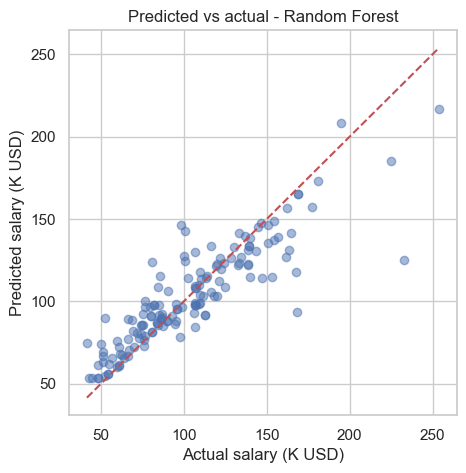

In [20]:
# Predicted vs actual salary for the best model (points near the red line = good predictions)
plt.figure(figsize=(5, 5))
plt.scatter(y_test, predictions[best_name], alpha=0.5)
low, high = y_test.min(), y_test.max()
plt.plot([low, high], [low, high], "r--")
plt.xlabel("Actual salary (K USD)")
plt.ylabel("Predicted salary (K USD)")
plt.title(f"Predicted vs actual - {best_name}")
plt.show()

Points close to the red diagonal represent predictions close to the actual salaries. Points far from the line indicate larger errors. A pattern where predictions are too low for high salaries or too high for low salaries suggests the model may struggle at the extremes or pull predictions toward the average.

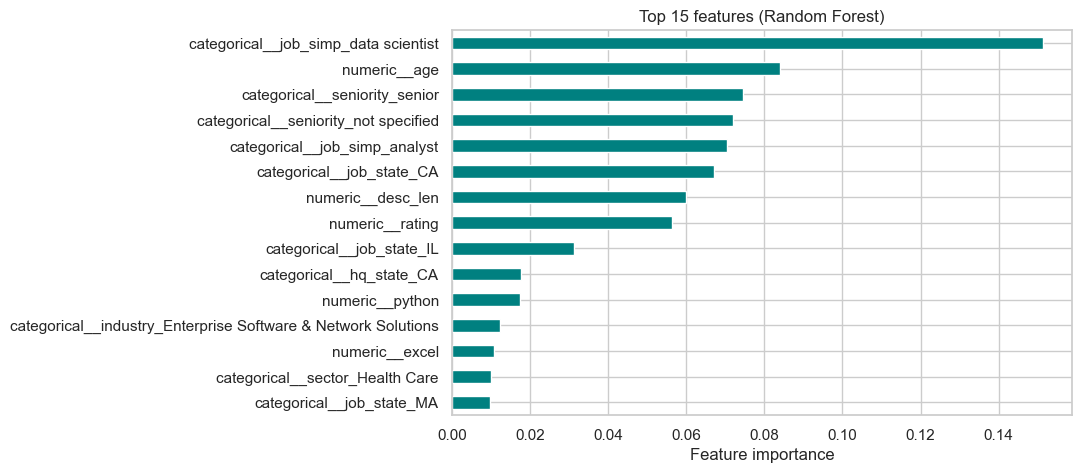

In [21]:
# Feature importance for Random Forest (where supported)
rf_model = models["Random Forest"]
rf_model.fit(X_train, y_train)

feature_names = rf_model.named_steps["preprocessing"].get_feature_names_out()
importances = rf_model.named_steps["model"].feature_importances_

importance = pd.Series(importances, index=feature_names).sort_values().tail(15)

plt.figure(figsize=(8, 5))
importance.plot(kind="barh", color="teal")
plt.title("Top 15 features (Random Forest)")
plt.xlabel("Feature importance")
plt.show()

The feature-importance chart ranks the features the Random Forest model relied on most when making predictions. Higher importance indicates greater contribution to the model's splits, not that a feature causes salary changes. One-hot encoded categories appear as separate features, and importance should be interpreted alongside domain knowledge and model limitations.

## Step 7: Predict salary for a sample job

Enter values using the same raw columns used by the model. Unknown categories are handled by the preprocessing pipeline.

In [22]:
new_job = pd.DataFrame([{
    "rating": 4.1,
    "age": 25,
    "desc_len": 3000,
    "same_state": 1,
    "python": 1,
    "excel": 0,
    "sql": 1,
    "spark": 1,
    "aws": 1,
    "tableau": 0,
    "tensorflow": 0,
    "hadoop": 0,
    "job_simp": "data scientist",
    "seniority": "senior",
    "job_state": "CA",
    "hq_state": "CA",
    "size": "1001 to 5000 employees",
    "ownership": "Company - Public",
    "industry": "unknown",
    "sector": "Information Technology",
    "revenue": "unknown"
}])

best_name = results.iloc[0]["Model"]
best_model = models[best_name]
predicted_salary = best_model.predict(new_job)[0]

print("Selected model:", best_name)
print(f"Predicted average salary: ${predicted_salary:.1f}K per year")

Selected model: Random Forest
Predicted average salary: $144.8K per year


### Step 8: Conclusion

The analysis of Glassdoor job-posting data highlights how salary varies across job roles, seniority levels, locations, company characteristics, and required technical skills. The exploratory analysis helps identify patterns in compensation and shows why job-related features are important when building a salary prediction model.

- **Job roles and seniority:** Salary differences across job titles and experience levels indicate that compensation depends on both the nature of the role and its level of responsibility. Grouping job titles into broader categories can help the model learn these patterns more effectively.
- **Location-based differences:** Salary variations across states suggest that geographic location is an important feature. However, these differences may also reflect variations in living costs, employer demand, and the concentration of specialized jobs.
- **Technical skills:** Differences in salaries across skill requirements can help identify skills associated with higher compensation. These relationships should be interpreted as associations rather than proof that a particular skill directly increases salary.
- **Model comparison:** Linear Regression provides a baseline, Ridge Regression helps control large coefficients, and tree-based models such as Random Forest and Gradient Boosting can capture nonlinear relationships and interactions between features.
- **Model evaluation:** MAE and RMSE measure the magnitude of prediction errors, while R² measures the proportion of salary variation explained by the model. Comparing all three metrics helps assess predictive performance more reliably than using R² alone.
- **Feature importance:** Random Forest feature importance helps identify which input features contribute most to predictions, providing a useful starting point for understanding the model's behavior.

Overall, the project demonstrates how job-posting data can be transformed into a salary estimation tool. Its practical value lies in identifying compensation patterns and generating approximate salary estimates for different job profiles. The reference project reports an R² of approximately **0.72** in its own setup; the final performance of this implementation should be judged using its actual test-set results. Further improvements could include better handling of outliers, more detailed experience-level features, and cross-validation to assess model reliability.